In [1]:
println("Ядро отвечает. Julia ", VERSION)
OUT = abspath("lab06_lite_results")
mkpath(OUT)
checks = Pair{String,Float64}[]
function check(name, err, tol)
    @assert isfinite(err) && err <= tol "$name: $err > $tol"
    push!(checks, name=>Float64(err))
    println("PASS: ",name,"; ошибка = ",err)
end

function rk4(f,u0,T; h=0.01)
    steps = ceil(Int,T/h)
    t = collect(range(0.0,T;length=steps+1))
    dt = T/steps
    U = zeros(length(u0),steps+1)
    U[:,1] = u0
    for j in 1:steps
        u = U[:,j]
        k1 = f(u,t[j])
        k2 = f(u + dt/2*k1,t[j]+dt/2)
        k3 = f(u + dt/2*k2,t[j]+dt/2)
        k4 = f(u + dt*k3,t[j]+dt)
        U[:,j+1] = u + dt/6*(k1+2*k2+2*k3+k4)
    end
    @assert all(isfinite,U) "Решение содержит NaN/Inf"
    return t,U
end

struct LiteSVG
    source::String
end
Base.show(io::IO, ::MIME"image/svg+xml", img::LiteSVG) = print(io,img.source)
esc(s) = replace(string(s),"&"=>"&amp;","<"=>"&lt;",">"=>"&gt;","\""=>"&quot;")

function chart(series,labels,name; title=name,xlabel="t",ylabel="Значение",animate=false)
    colors = ["#2563eb","#dc2626","#16a34a","#9333ea","#d97706","#0891b2"]
    xmin = minimum(minimum(s[1]) for s in series)
    xmax = maximum(maximum(s[1]) for s in series)
    ymin = minimum(minimum(s[2]) for s in series)
    ymax = maximum(maximum(s[2]) for s in series)
    dx = max(xmax-xmin,1e-9)
    dy = max(ymax-ymin,1e-9)
    X(x) = 80 + 680*(x-xmin)/dx
    Y(y) = 410 - 320*(y-ymin)/dy
    io=IOBuffer()
    print(io,"<svg xmlns='http://www.w3.org/2000/svg' width='900' height='520' viewBox='0 0 900 520'>")
    print(io,"<rect width='900' height='520' fill='white'/><g font-family='sans-serif' font-size='13' fill='#111827'>")
    print(io,"<text x='80' y='28' font-size='19'>",esc(title),"</text>")
    for k in 0:4
        x=xmin+k*dx/4; y=ymin+k*dy/4
        print(io,"<path d='M ",X(x)," 90 V 410 M 80 ",Y(y)," H 760' stroke='#e5e7eb' fill='none'/>")
        print(io,"<text x='",X(x),"' y='432' text-anchor='middle'>",round(x;sigdigits=4),"</text>")
        print(io,"<text x='73' y='",Y(y)+4,"' text-anchor='end'>",round(y;sigdigits=4),"</text>")
    end
    print(io,"<path d='M 80 90 V 410 H 760' fill='none' stroke='#374151'/>")
    print(io,"<text x='420' y='465'>",esc(xlabel),"</text><text x='12' y='65'>",esc(ylabel),"</text>")
    for (j,(xs,ys)) in enumerate(series)
        @assert length(xs)==length(ys)
        idx=unique(round.(Int,range(1,length(xs);length=min(1600,length(xs)))))
        points=join([string(round(X(xs[k]);digits=2),",",round(Y(ys[k]);digits=2)) for k in idx]," ")
        color=colors[mod1(j,length(colors))]
        print(io,"<polyline points='",points,"' stroke='",color,"' stroke-width='1.6' fill='none'/>")
        if animate
            pathdata = "M " * replace(points," "=>" L ")
            print(io,"<circle r='5' fill='",color,"'><animateMotion dur='8s' repeatCount='indefinite' path='",pathdata,"'/></circle>")
        end
        print(io,"<text x='",80+210*mod(j-1,3),"' y='",490+16*div(j-1,3),"' fill='",color,"'>",esc(labels[j]),"</text>")
    end
    print(io,"</g></svg>")
    svg=String(take!(io))
    write(joinpath(OUT,name*".svg"),svg)
    display(LiteSVG(svg))
    return nothing
end
function table(name,t,U,labels)
    open(joinpath(OUT,name*".csv"),"w") do io
        println(io,join(vcat(["t"],labels),","))
        for j in eachindex(t)
            println(io,join(vcat([t[j]],U[:,j]),","))
        end
    end
end
println("Подготовка завершена. Пакеты не загружались.")

Ядро отвечает. Julia 1.10.3
Подготовка завершена. Пакеты не загружались.


## Примеры 6.2: экспонента, Лоренц, Лотка–Вольтерра
Экспонента: $u'=0.98u$, $u_0=1$, $t\in[0,1]$, точное решение $e^{0.98t}$.
Лоренц: параметры $(10,28,8/3)$, $(x_0,y_0,z_0)=(1,0,0)$, $[0,100]$.
Лотка–Вольтерра: $x'=1.5x-xy$, $y'=-3y+xy$, начальное состояние $(1,1)$.

Изображение Лоренца — проекция x–z; отдельного сравнения интерполяций решателя в LITE нет. Длительная хаотическая траектория не должна трактоваться как точный поточечный прогноз.

PASS: Экспонента; ошибка = 1.9907009374264817e-10


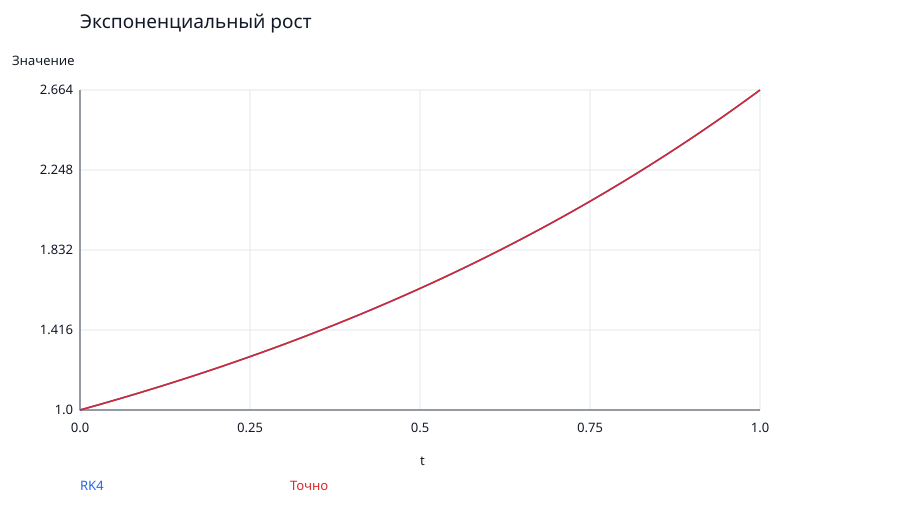

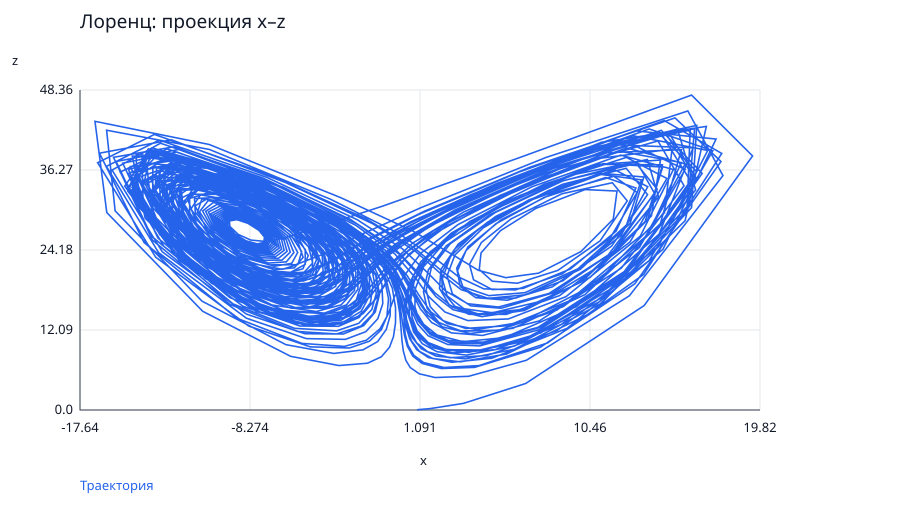

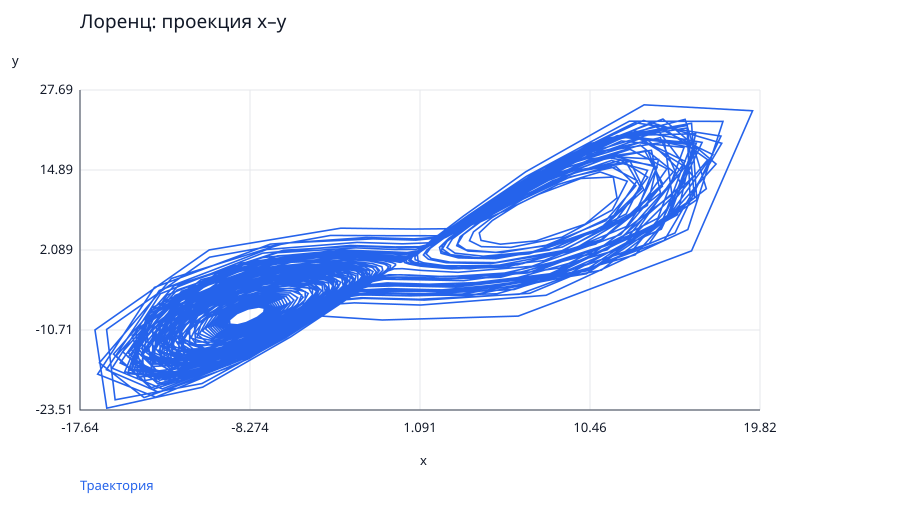

PASS: Первый интеграл Лотки–Вольтерры; ошибка = 3.040399487730383e-9


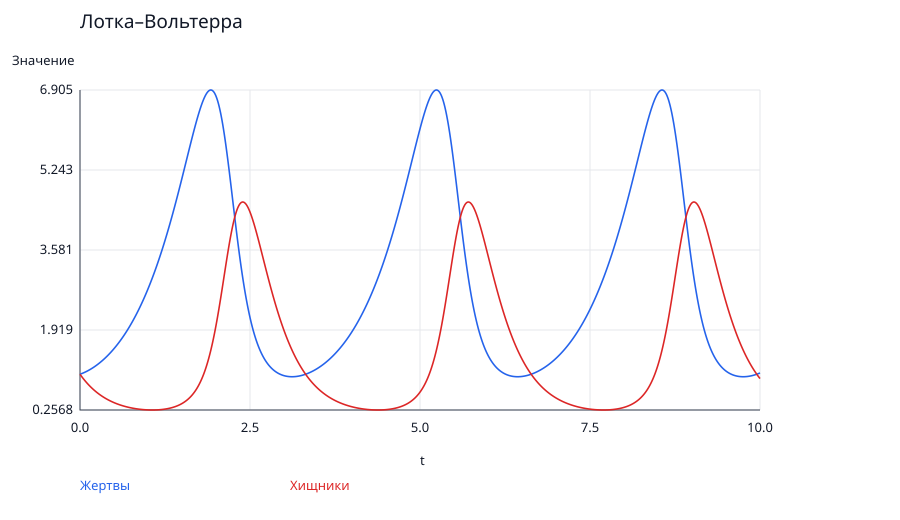

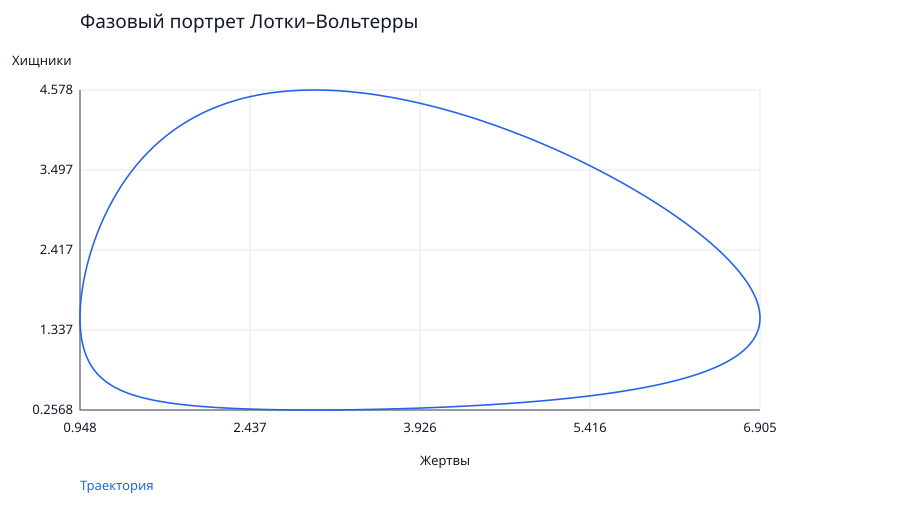

In [2]:
te,ue = rk4((u,t)->[0.98*u[1]],[1.0],1.0;h=0.01)
check("Экспонента",maximum(abs.(ue[1,:]-exp.(0.98.*te))),1e-7)
chart([(te,ue[1,:]),(te,exp.(0.98.*te))],["RK4","Точно"],"01_exponential";title="Экспоненциальный рост")
lorenz(u,t) = [10*(u[2]-u[1]),u[1]*(28-u[3])-u[2],u[1]*u[2]-8/3*u[3]]
tl,ul = rk4(lorenz,[1.0,0.0,0.0],100.0;h=0.005)
chart([(ul[1,:],ul[3,:])],["Траектория"],"02_lorenz_xz";title="Лоренц: проекция x–z",xlabel="x",ylabel="z")
chart([(ul[1,:],ul[2,:])],["Траектория"],"03_lorenz_xy";title="Лоренц: проекция x–y",xlabel="x",ylabel="y")
lv(u,t) = [1.5*u[1]-u[1]*u[2],-3*u[2]+u[1]*u[2]]
tv,uv = rk4(lv,[1.0,1.0],10.0;h=0.005)
@assert minimum(uv)>0
H=uv[1,:]-3 .*log.(uv[1,:])+uv[2,:]-1.5 .*log.(uv[2,:])
check("Первый интеграл Лотки–Вольтерры",maximum(abs.(H.-H[1])),1e-5)
chart([(tv,uv[1,:]),(tv,uv[2,:])],["Жертвы","Хищники"],"04_lv_time";title="Лотка–Вольтерра")
chart([(uv[1,:],uv[2,:])],["Траектория"],"05_lv_phase";title="Фазовый портрет Лотки–Вольтерры",xlabel="Жертвы",ylabel="Хищники")
table("exponential",te,ue,["u"]); table("lorenz",tl,ul,["x","y","z"]);table("lotka_volterra",tv,uv,["x","y"])

## 1. Модель Мальтуса
$x'=(b-c)x$. При $x_0=100$ выбраны $a=b-c=0.2,0,-0.1$ для роста, постоянства и убывания. Например, $(b,c)=(0.3,0.1),(0.1,0.1),(0.05,0.15)$. Время — условные годы. Модель не учитывает конечность ресурсов.
## 2. Логистическая модель
$x'=rx(1-x/K)$, $r=0.5$, $K=1000$, $x_0=50,500,1500$. Это старт ниже и выше ёмкости среды. Для положительных решений предел — $K$.
Точное решение $K/[1+(K/x_0-1)e^{-rt}]$.

PASS: Мальтус 1; ошибка = 1.8048385754809715e-6
PASS: Мальтус 2; ошибка = 0.0
PASS: Мальтус 3; ошибка = 1.9240076198911993e-10


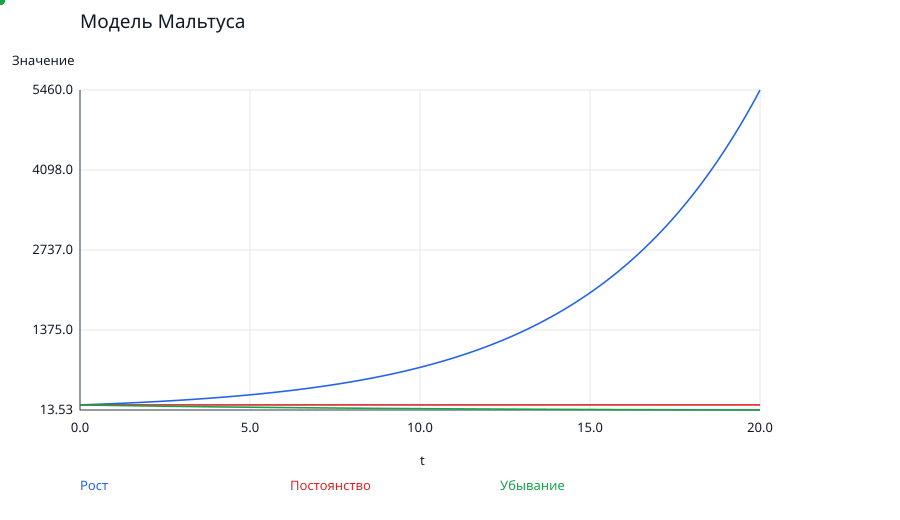

PASS: Логистика 1; ошибка = 2.2968265511735808e-8
PASS: Логистика 2; ошибка = 4.594198799168225e-9
PASS: Логистика 3; ошибка = 6.40234247839544e-8


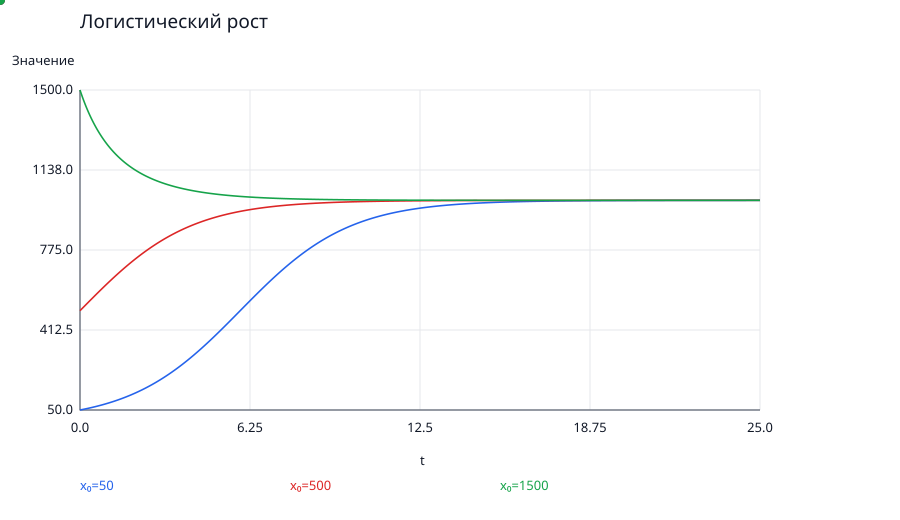

In [3]:
m_cases=[0.2,0.0,-0.1]
m_series=[]
for (j,a) in enumerate(m_cases)
    t,U=rk4((u,t)->[a*u[1]],[100.0],20.0;h=0.05)
    check("Мальтус $j",maximum(abs.(U[1,:]-100 .*exp.(a.*t))),1e-4)
    push!(m_series,(t,U[1,:]))
    table("malthus_$j",t,U,["x"])
end
chart(m_series,["Рост","Постоянство","Убывание"],"06_malthus";title="Модель Мальтуса",animate=true)
log_series=[]
for (j,x0) in enumerate([50.0,500.0,1500.0])
    t,U=rk4((u,t)->[0.5*u[1]*(1-u[1]/1000)],[x0],25.0;h=0.02)
    exact=1000 ./ (1 .+ (1000/x0-1).*exp.(-0.5.*t))
    check("Логистика $j",maximum(abs.(U[1,:]-exact)),1e-4)
    push!(log_series,(t,U[1,:]))
    table("logistic_$j",t,U,["x"])
end
chart(log_series,["x₀=50","x₀=500","x₀=1500"],"07_logistic";title="Логистический рост",animate=true)

## 3. SIR и 4. SEIR
$N=1000$, $S_0=990$, $I_0=10$, $R_0=0$. Контактный параметр $b=0.3$ в день, выздоровление $\nu=\gamma=0.1$ в день.
В ненормированной записи SIR из задания берём $\beta=b/N=0.0003$: $S'=-\beta SI$, $I'=\beta SI-\nu I$, $R'=\nu I$.
SEIR: $S'=-bSI/N$, $E'=bSI/N-\delta E$, $I'=\delta E-\gamma I$, $R'=\gamma I$; $E_0=0$, $\delta=0.2$ в день. Начальные S, I, R согласованы. Параметры учебные, не медицинский прогноз.
Проверяем сохранение $N$, неотрицательность и сравниваем пики по сетке.

PASS: SIR: население; ошибка = 1.0231815394945443e-12
PASS: SIR: неотрицательность; ошибка = 0.0
PASS: SEIR: население; ошибка = 2.6147972675971687e-12
PASS: SEIR: неотрицательность; ошибка = 0.0


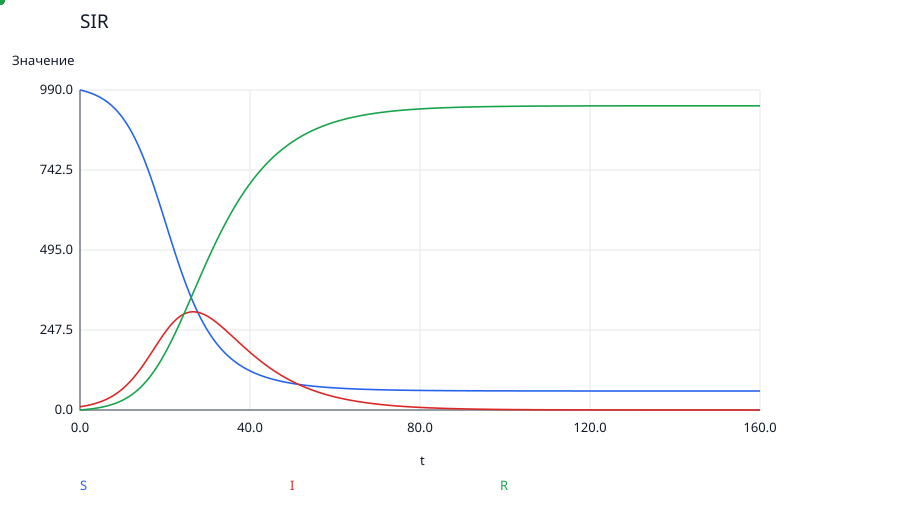

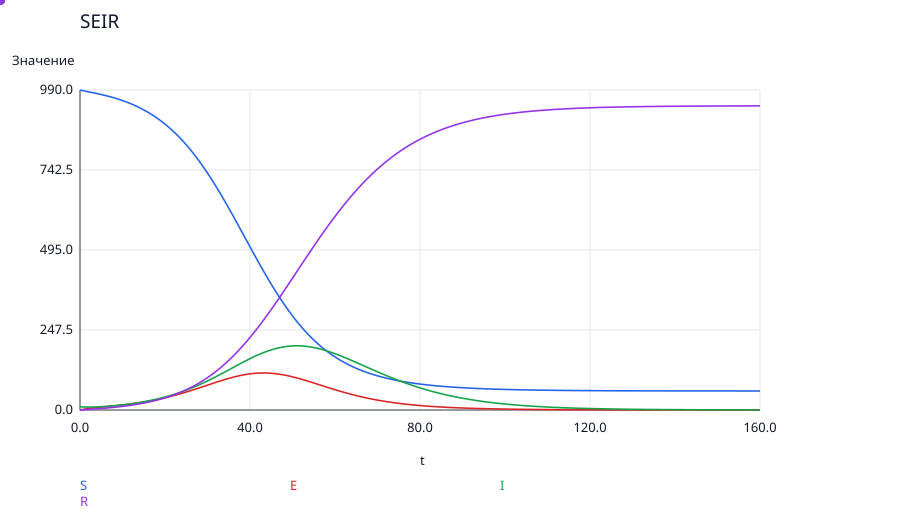

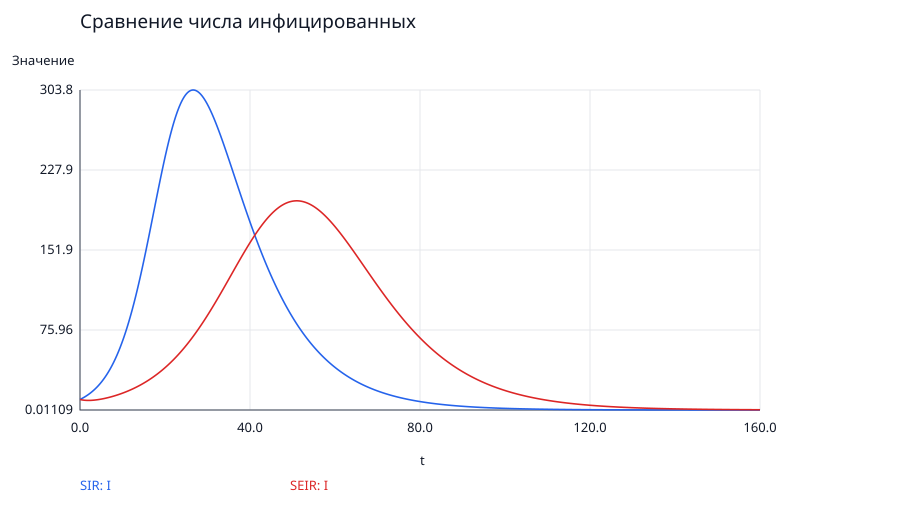

SIR: пик I=303.811; день 26.6 (шаг 0.1)
SEIR: пик I=198.605; день 51.0 (шаг 0.1)


In [4]:
sir(u,t) = [-0.0003*u[1]*u[2],0.0003*u[1]*u[2]-0.1*u[2],0.1*u[2]]
seir(u,t) = [-0.0003*u[1]*u[3],0.0003*u[1]*u[3]-0.2*u[2],0.2*u[2]-0.1*u[3],0.1*u[3]]
ts,us=rk4(sir,[990.0,10.0,0.0],160.0;h=0.1)
tse,use=rk4(seir,[990.0,0.0,10.0,0.0],160.0;h=0.1)
for (name,U) in [("SIR",us),("SEIR",use)]
    check("$name: население",maximum(abs.(vec(sum(U;dims=1)).-1000)),1e-7)
    check("$name: неотрицательность",max(0.0,-minimum(U)),1e-8)
end
chart([(ts,us[j,:]) for j in 1:3],["S","I","R"],"08_sir";title="SIR",animate=true)
chart([(tse,use[j,:]) for j in 1:4],["S","E","I","R"],"09_seir";title="SEIR",animate=true)
chart([(ts,us[2,:]),(tse,use[3,:])],["SIR: I","SEIR: I"],"10_comparison";title="Сравнение числа инфицированных")
for (name,t,I) in [("SIR",ts,us[2,:]),("SEIR",tse,use[3,:])]
    k=argmax(I)
    println(name,": пик I=",round(I[k];digits=3),"; день ",t[k]," (шаг 0.1)")
end
table("sir",ts,us,["S","I","R"]);table("seir",tse,use,["S","E","I","R"])

## 5. Дискретная модель Лотки–Вольтерры
$X_{n+1}=2X_n(1-X_n)-X_nY_n$, $Y_{n+1}=-Y_n+5X_nY_n$.
Неподвижные точки: $(0,0)$, $(0.5,0)$, $(0.4,0.2)$.
В начале собственные числа $(2,-1)$, во второй точке $(0,1.5)$ — обе неустойчивы. В положительной точке $\lambda=0.6\pm i\sqrt{0.24}$, $|\lambda|=\sqrt{0.6}<1$: локально устойчивый фокус.
При малом возмущении аналитическая линеаризация $z_n\approx z_*+J_*^n(z_0-z_*)$, $J_*=[0.2\ {-0.4};1\ 1]$ сравнивается с нелинейными итерациями. Это не точное общее решение нелинейной рекурсии. Точное стационарное решение — $z_n=z_*$.
Начальное состояние $(0.401,0.199)$ выбрано близко к положительному равновесию. В произвольной области отображение не гарантирует положительности.

PASS: Равновесие [0.0, 0.0]; ошибка = 0.0
PASS: Равновесие [0.5, 0.0]; ошибка = 0.0
PASS: Равновесие [0.4, 0.2]; ошибка = 5.551115123125783e-17
PASS: Сходимость к положительному равновесию; ошибка = 2.1359275459431615e-10
Максимальная ошибка линеаризации: 6.014975000023792e-6


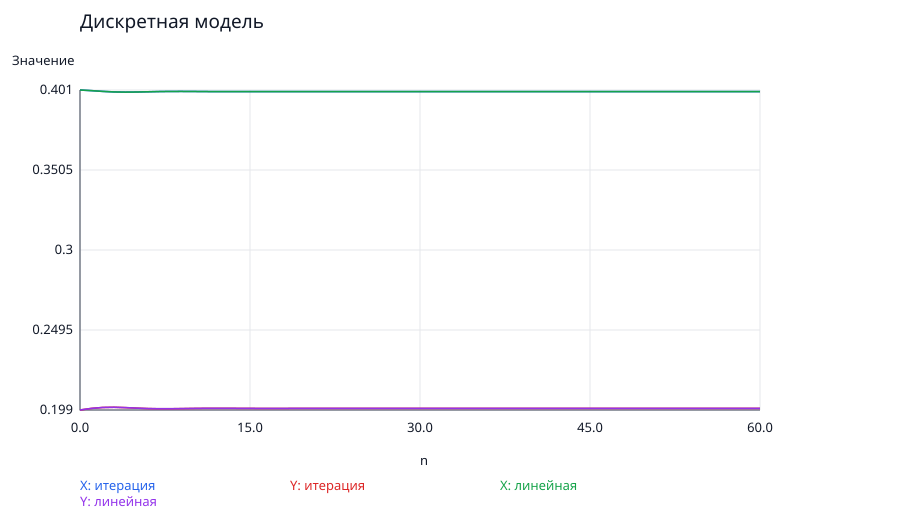

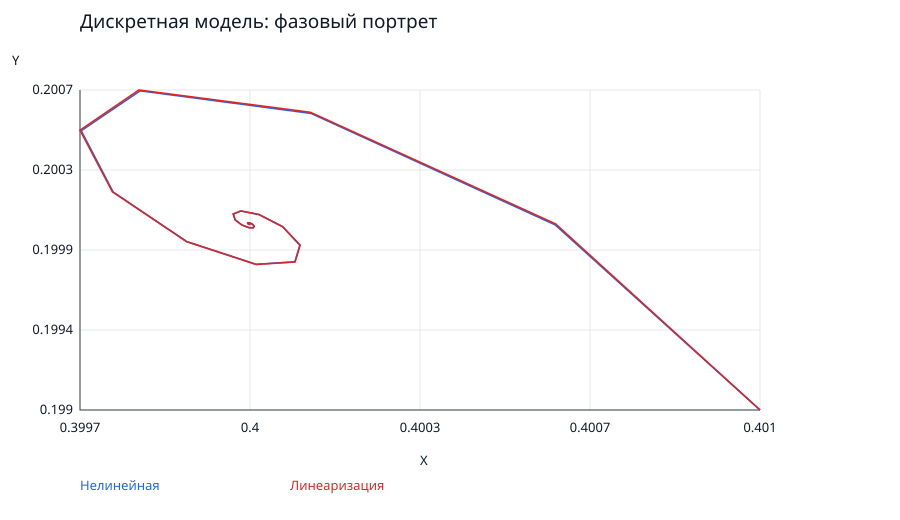

In [5]:
F(z)=[2*z[1]*(1-z[1])-z[1]*z[2],-z[2]+5*z[1]*z[2]]
zstar=[0.4,0.2]
for z in [[0.0,0.0],[0.5,0.0],zstar]
    check("Равновесие $z",maximum(abs.(F(z)-z)),1e-14)
end
J=[0.2 -0.4;1.0 1.0]
Z=zeros(2,61); L=zeros(2,61)
Z[:,1]=[0.401,0.199]
for k in 1:60
    Z[:,k+1]=F(Z[:,k])
end
for k in 0:60
    L[:,k+1]=zstar+J^k*(Z[:,1]-zstar)
end
check("Сходимость к положительному равновесию",maximum(abs.(Z[:,end]-zstar)),1e-7)
println("Максимальная ошибка линеаризации: ",maximum(abs.(Z-L)))
chart([(0:60,Z[1,:]),(0:60,Z[2,:]),(0:60,L[1,:]),(0:60,L[2,:])],
      ["X: итерация","Y: итерация","X: линейная","Y: линейная"],"11_discrete_time";title="Дискретная модель",xlabel="n")
chart([(Z[1,:],Z[2,:]),(L[1,:],L[2,:])],["Нелинейная","Линеаризация"],"12_discrete_phase";
      title="Дискретная модель: фазовый портрет",xlabel="X",ylabel="Y")
table("discrete",0:60,vcat(Z,L),["X","Y","X_linear","Y_linear"])

## 6. Конкурентный отбор
$x'=\alpha x-\beta xy$, $y'=\alpha y-\beta xy$; $\alpha=0.4$, $\beta=0.02$, $(x_0,y_0)=(12,10)$. Небольшое начальное преимущество позволяет исследовать отбор.
Разность $x-y=(x_0-y_0)e^{\alpha t}$ усиливается. При $x_0=y_0$ обе популяции следуют одному логистическому уравнению с $K=20$. Положительное равновесие $(20,20)$ — седло: симметрия не означает устойчивость к любому возмущению. Модель не ограничивает собственными ресурсами рост победителя.

PASS: Конкуренция: аналитическая разность; ошибка = 1.0289113561157137e-8


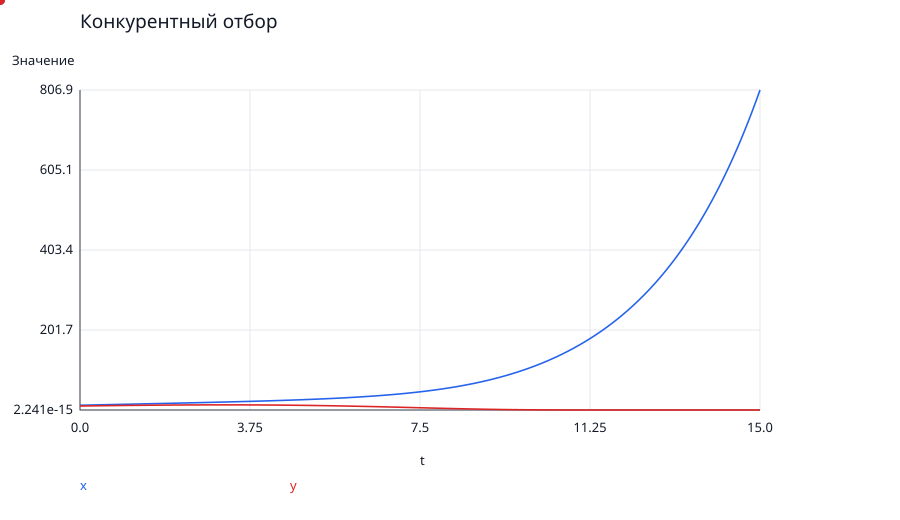

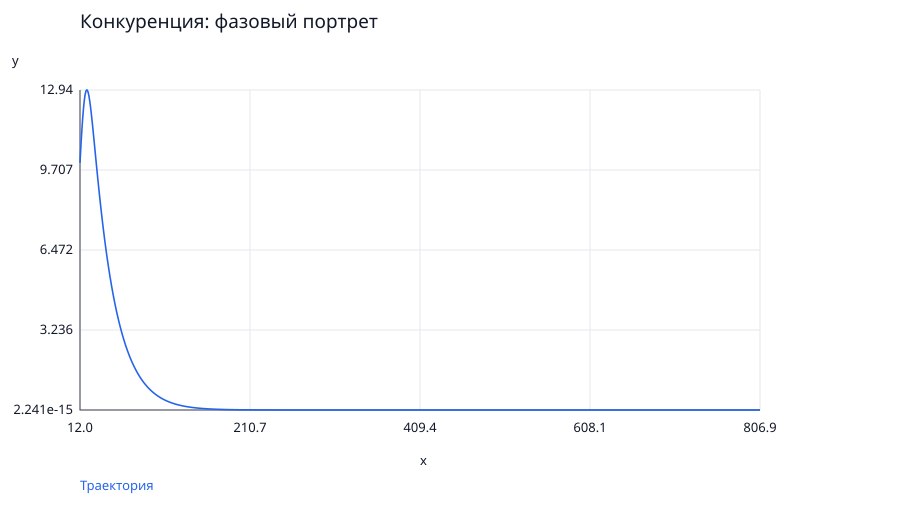

In [6]:
comp(u,t)=[0.4*u[1]-0.02*u[1]*u[2],0.4*u[2]-0.02*u[1]*u[2]]
tc,uc=rk4(comp,[12.0,10.0],15.0;h=0.01)
check("Конкуренция: аналитическая разность",maximum(abs.(uc[1,:]-uc[2,:]-2 .*exp.(0.4.*tc))),1e-5)
chart([(tc,uc[1,:]),(tc,uc[2,:])],["x","y"],"13_competition";title="Конкурентный отбор",animate=true)
chart([(uc[1,:],uc[2,:])],["Траектория"],"14_competition_phase";title="Конкуренция: фазовый портрет",xlabel="x",ylabel="y")
table("competition",tc,uc,["x","y"])

## 7. Консервативный и 8. затухающий осцилляторы
$x'=y$, $y'=-\omega_0^2x-2\gamma y$. Выбраны $\omega_0=2$, $x_0=1$, $y_0=0$, интервал $[0,20]$.
При $\gamma=0$: $x=\cos 2t$, $y=-2\sin 2t$, $E=(y^2+4x^2)/2$ постоянна.
При $\gamma=0.2$: $\Omega=\sqrt{4-\gamma^2}$, $x=e^{-\gamma t}[\cos\Omega t+(\gamma/\Omega)\sin\Omega t]$, энергия убывает: $E'=-2\gamma y^2$.
Начальные данные позволяют просто проверить точное решение. Фазовые кривые — эллипс и спираль. Дополнительно сравним критическое затухание $\gamma=2$ и апериодический режим $\gamma=3$.

PASS: Осциллятор conservative: x; ошибка = 5.239717233707086e-8
PASS: Сохранение энергии; ошибка = 3.555373773167503e-9


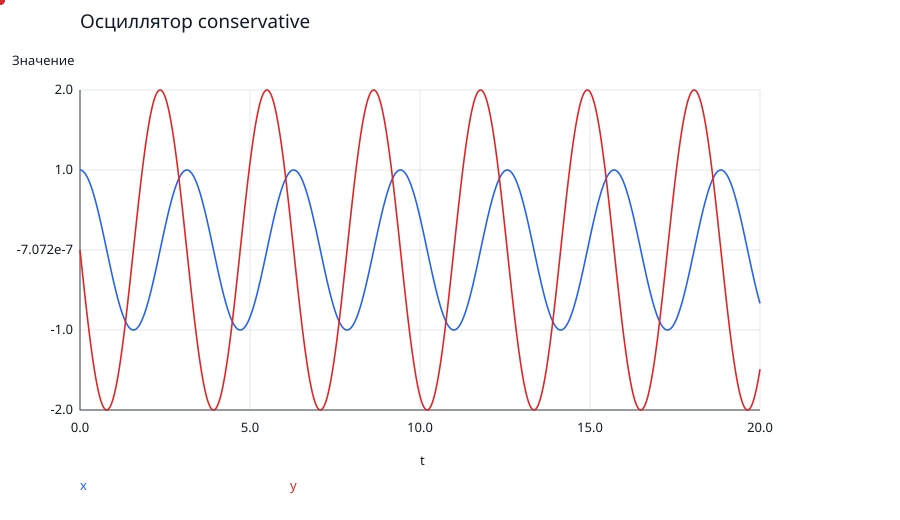

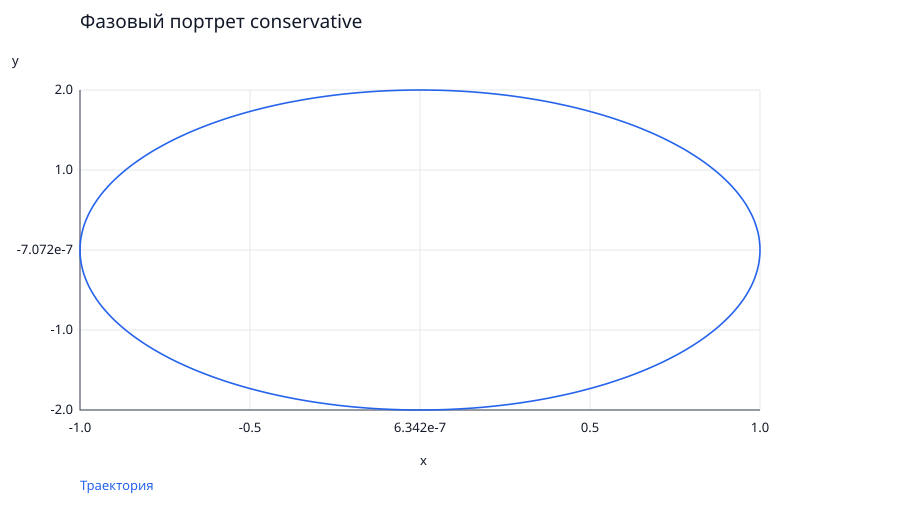

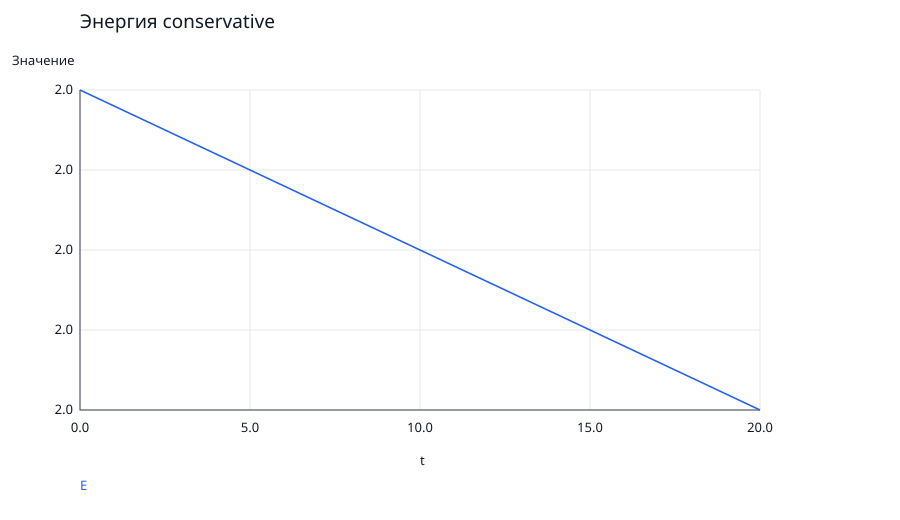

PASS: Осциллятор damped: x; ошибка = 4.927620644856745e-9
PASS: Отсутствие роста энергии; ошибка = 0.0


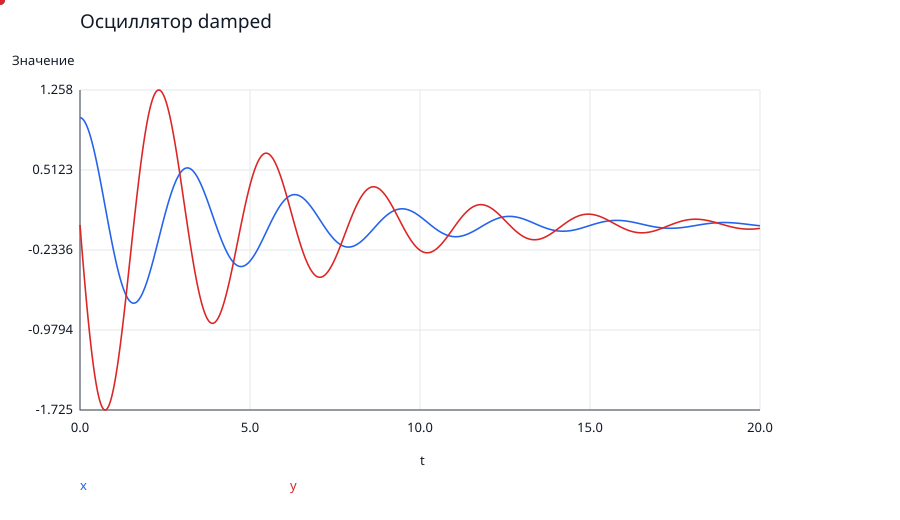

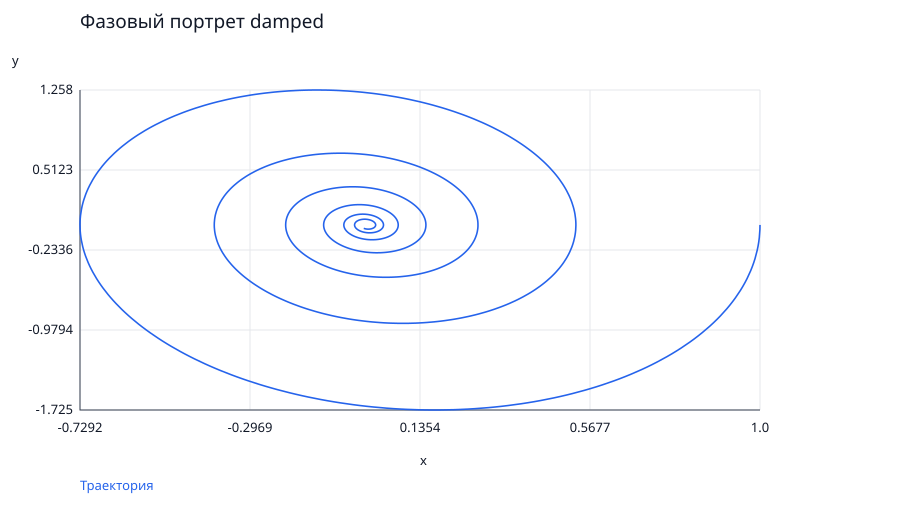

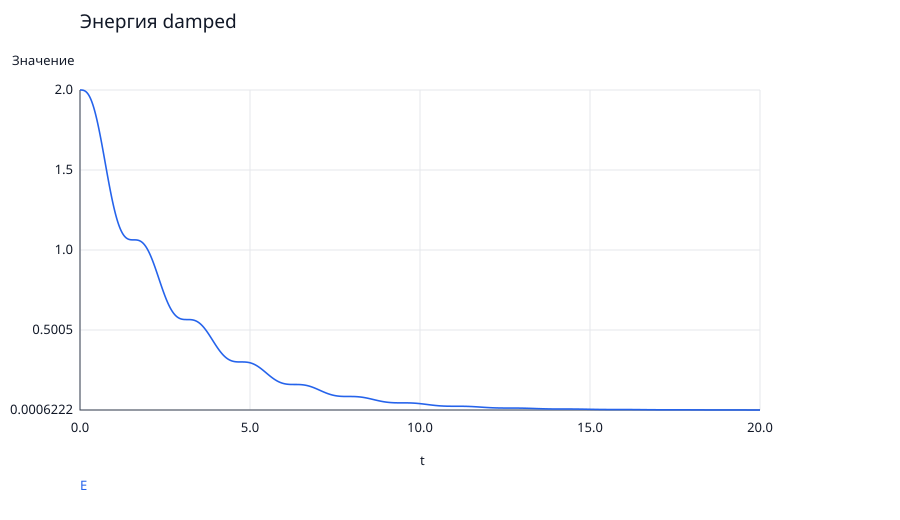

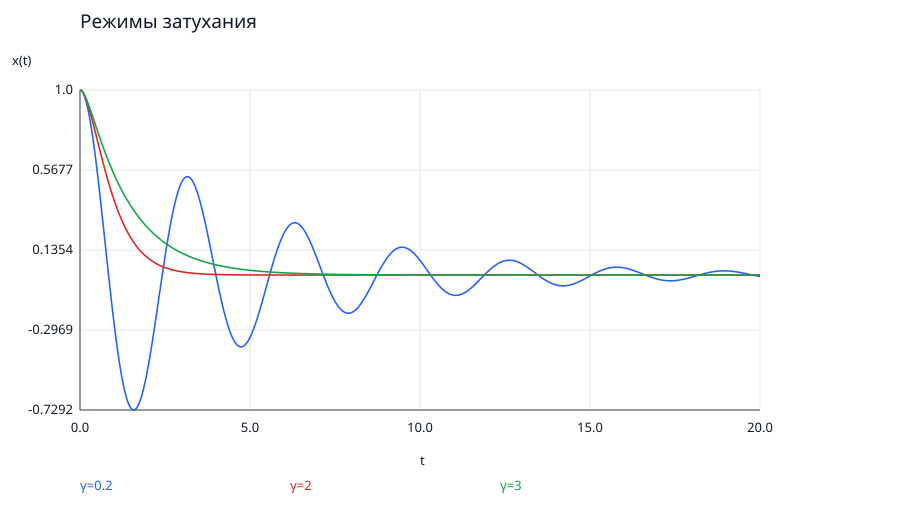

In [7]:
regimes=[]
for (tag,g) in [("conservative",0.0),("damped",0.2)]
    f=(u,t)->[u[2],-4*u[1]-2*g*u[2]]
    t,U=rk4(f,[1.0,0.0],20.0;h=0.01)
    om=sqrt(4-g^2)
    exact=exp.(-g.*t).*(cos.(om.*t)+(g/om).*sin.(om.*t))
    check("Осциллятор $tag: x",maximum(abs.(U[1,:]-exact)),1e-6)
    E=(U[2,:].^2+4 .*U[1,:].^2)./2
    if g==0
        check("Сохранение энергии",maximum(abs.(E.-E[1])),1e-6)
    else
        check("Отсутствие роста энергии",max(0.0,maximum(diff(E))),1e-8)
    end
    chart([(t,U[1,:]),(t,U[2,:])],["x","y"],"osc_$tag";title="Осциллятор $tag",animate=true)
    chart([(U[1,:],U[2,:])],["Траектория"],"phase_$tag";title="Фазовый портрет $tag",xlabel="x",ylabel="y")
    chart([(t,E)],["E"],"energy_$tag";title="Энергия $tag")
    table("osc_$tag",t,vcat(U,permutedims(E)),["x","y","energy"])
end
for g in [0.2,2.0,3.0]
    t,U=rk4((u,t)->[u[2],-4*u[1]-2*g*u[2]],[1.0,0.0],20.0;h=0.01)
    push!(regimes,(t,U[1,:]))
end
chart(regimes,["γ=0.2","γ=2","γ=3"],"damping_regimes";title="Режимы затухания",ylabel="x(t)")

## Контроль шага и итог
Для экспоненты и консервативного осциллятора дополнительно сравниваем h и h/2 с точным решением. Это локальная проверка реализации, а не доказательство точности всех моделей. Для научного расчёта нужны дополнительные исследования сходимости.

Выводы: знак коэффициента Мальтуса определяет рост; логистика ограничивает положительные решения ёмкостью среды; SIR/SEIR сохраняют население; латентная стадия меняет динамику эпидемии; положительное равновесие дискретной модели локально устойчиво; конкуренция усиливает разность; энергия осциллятора сохраняется или убывает в зависимости от затухания.

Для сдачи: заполните группу, сохраните выполненный notebook и сделайте скриншоты. LITE не демонстрирует работу специализированных пакетов из цели лабораторной — при строгом требовании использовать их нужен исходный полный вариант после исправления среды.
Источник: предоставленный `006-lab_f_du.pdf`, разделы 6.2–6.5.

In [8]:
for h in [0.02,0.01]
    t,U=rk4((u,t)->[u[2],-4*u[1]],[1.0,0.0],20.0;h=h)
    println("Осциллятор: h=",h,"; ошибка x=",maximum(abs.(U[1,:]-cos.(2 .*t))))
end
open(joinpath(OUT,"checks.txt"),"w") do io
    println(io,"Julia ",VERSION,"; RK4, без внешних пакетов")
    for (name,value) in checks
        println(io,"PASS | ",name," | ",value)
    end
end
println("Готово. Пройдено проверок: ",length(checks))
println("Результаты: ",OUT)
println("Сохраните ноутбук через File → Save Notebook.")

Осциллятор: h=0.02; ошибка x=8.386955567540877e-7
Осциллятор: h=0.01; ошибка x=5.239717233707086e-8
Готово. Пройдено проверок: 21
Результаты: /home/egorlisenkov/work/study/2026-2027/Компьютерный практикум по статистическому анализу данных/komputerni-praktikum-2026-2027/labs/lab06/lab06_lite_results
Сохраните ноутбук через File → Save Notebook.
